# Lab 4: Regression Analysis with Regularization Techniques

**Student:** Bharath Kumar Origanti  
**Course:** MSCS-634 — Advanced Big Data and Data Mining  
**Dataset:** Scikit-learn Diabetes dataset

**Goal:** Compare simple linear, multiple linear, polynomial, Ridge, and Lasso regression using a consistent held-out test set. Report MAE, MSE, RMSE, and R², and visualize predictions and regularization effects.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
OUTPUT_DIR = Path('figures')
OUTPUT_DIR.mkdir(exist_ok=True)
plt.rcParams['figure.figsize'] = (8, 5)

## Step 1: Load, explore, and prepare the dataset
The Diabetes dataset has 442 observations and ten numeric features. The target represents a quantitative measure of disease progression one year after baseline. We inspect shape, missing values, descriptive statistics, and target distribution.

Features: (442, 10) Target: (442,)
Missing feature values: 0 Missing targets: 0
Feature names: age, sex, bmi, bp, s1, s2, s3, s4, s5, s6


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136


,target
count,442.00
mean,152.13
std,77.09
min,25.00
25%,87.00
50%,140.50
75%,211.50
max,346.00


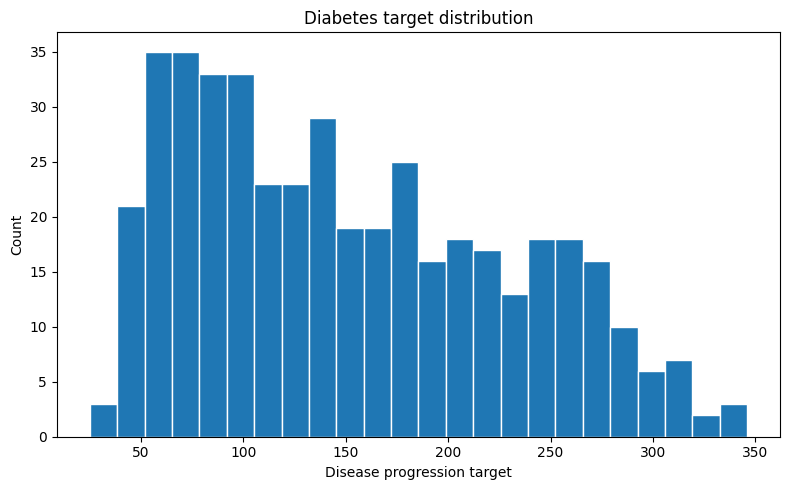

In [2]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()
print('Features:', X.shape, 'Target:', y.shape)
print('Missing feature values:', int(X.isna().sum().sum()), 'Missing targets:', int(y.isna().sum()))
print('Feature names:', ', '.join(X.columns))
display(X.describe().round(3))
display(y.describe().to_frame('target').round(2))
fig, ax = plt.subplots()
ax.hist(y, bins=24, edgecolor='white')
ax.set(title='Diabetes target distribution', xlabel='Disease progression target', ylabel='Count')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'target_distribution.png', dpi=160); plt.show()

The dataset contains no missing values, so imputation is unnecessary. We use an 80/20 train/test split. Feature scaling is fit only on training data through pipelines to avoid data leakage. The single-feature model uses BMI, a meaningful predictor of the target.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('BMI range:', X['bmi'].min(), 'to', X['bmi'].max())

Train: (353, 10) Test: (89, 10)
BMI range: -0.09027529589850945 to 0.17055522598064407


## Steps 2–5: Fit five regression models
Polynomial regression uses degree-2 terms on **BMI only**, avoiding the large number of interaction terms created by expanding all ten features. Ridge and Lasso use standardized predictors and `alpha=1.0`.

In [4]:
models = {
    'Simple Linear (BMI)': (LinearRegression(), ['bmi']),
    'Multiple Linear': (make_pipeline(StandardScaler(), LinearRegression()), list(X.columns)),
    'Polynomial Degree 2 (BMI)': (make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression()), ['bmi']),
    'Ridge (alpha=1)': (make_pipeline(StandardScaler(), Ridge(alpha=1.0)), list(X.columns)),
    'Lasso (alpha=1)': (make_pipeline(StandardScaler(), Lasso(alpha=1.0, max_iter=20000)), list(X.columns)),
}
results = []
predictions = {}
for name, (model, features) in models.items():
    model.fit(X_train[features], y_train)
    pred_train = model.predict(X_train[features])
    pred_test = model.predict(X_test[features])
    predictions[name] = pred_test
    results.append({
        'Model': name,
        'Train R²': r2_score(y_train, pred_train),
        'MAE': mean_absolute_error(y_test, pred_test),
        'MSE': mean_squared_error(y_test, pred_test),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred_test)),
        'R²': r2_score(y_test, pred_test)
    })
results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
display(results_df.round(3))
results_df.to_csv('model_metrics.csv', index=False)

,Model,Train R²,MAE,MSE,RMSE,R²
0,Lasso (alpha=1),0.523,42.803,2824.568,53.147,0.467
1,Ridge (alpha=1),0.528,42.812,2892.015,53.777,0.454
2,Multiple Linear,0.528,42.794,2900.194,53.853,0.453
3,Simple Linear (BMI),0.366,52.260,4061.826,63.732,0.233
4,Polynomial Degree 2 (BMI),0.367,52.384,4085.025,63.914,0.229


## Step 6: Visualize and compare model predictions
Points closer to the diagonal represent more accurate predictions. The same test observations are used for all models.

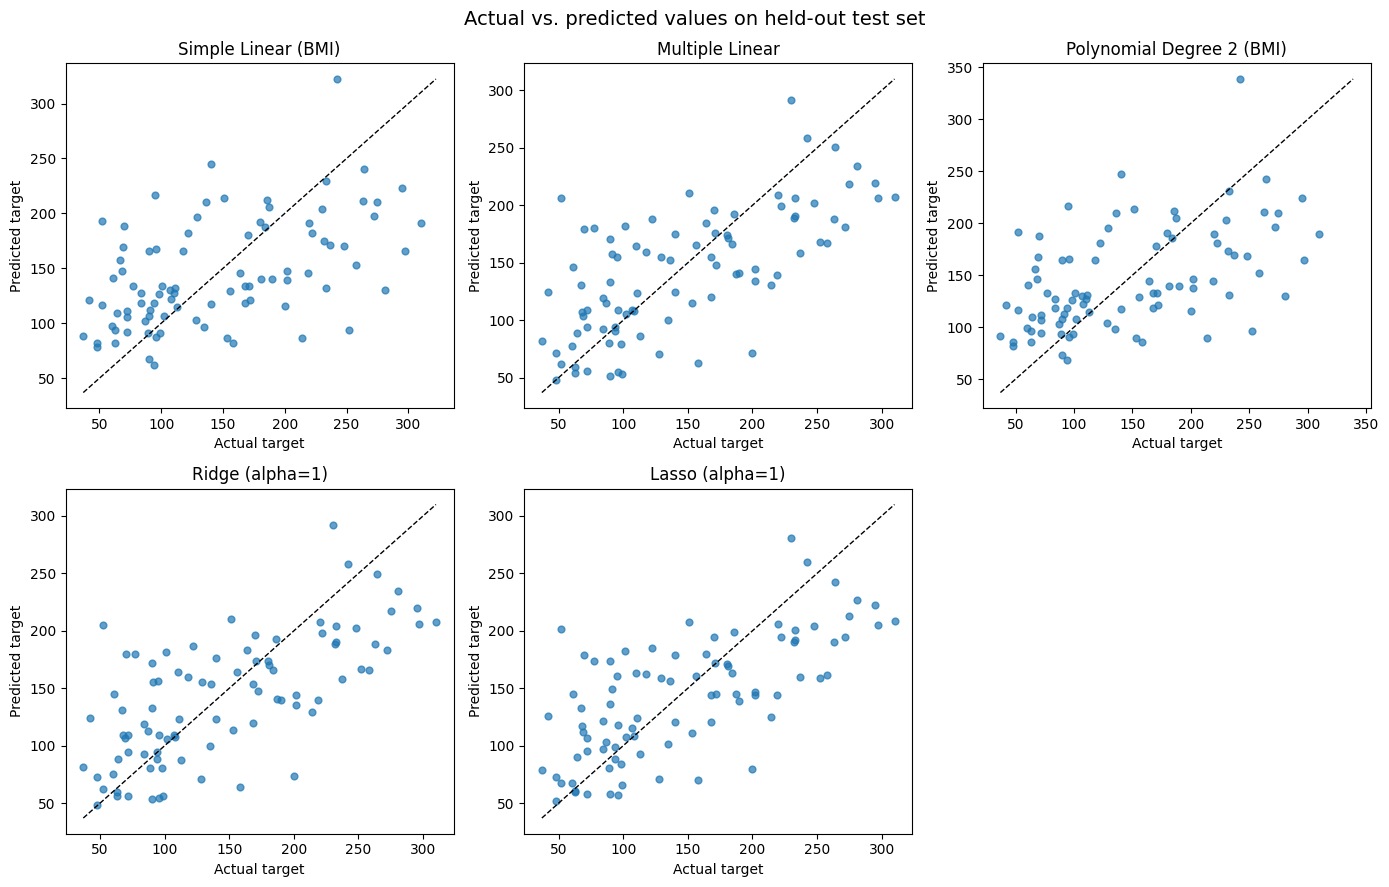

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, (name, pred) in zip(axes.flat, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.7, s=24)
    low = min(y_test.min(), pred.min()); high = max(y_test.max(), pred.max())
    ax.plot([low, high], [low, high], 'k--', lw=1)
    ax.set(title=name, xlabel='Actual target', ylabel='Predicted target')
for ax in list(axes.flat)[len(predictions):]: ax.axis('off')
fig.suptitle('Actual vs. predicted values on held-out test set', fontsize=14)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'actual_vs_predicted.png', dpi=160); plt.show()

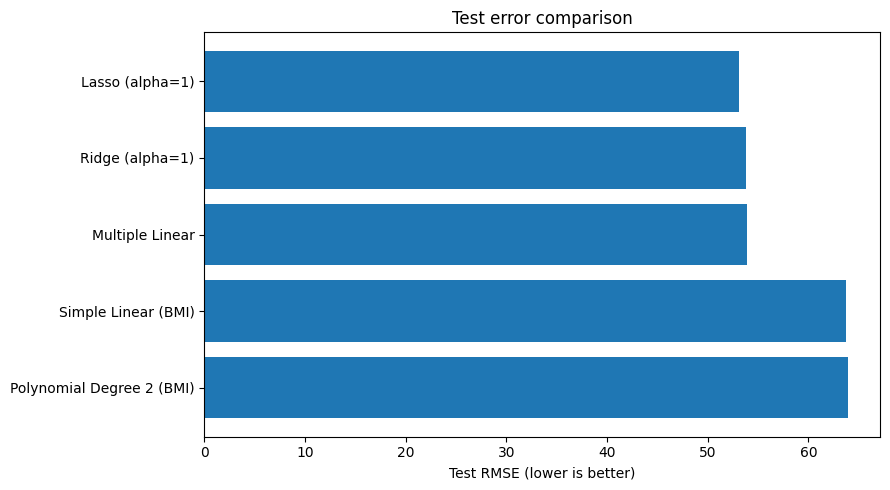

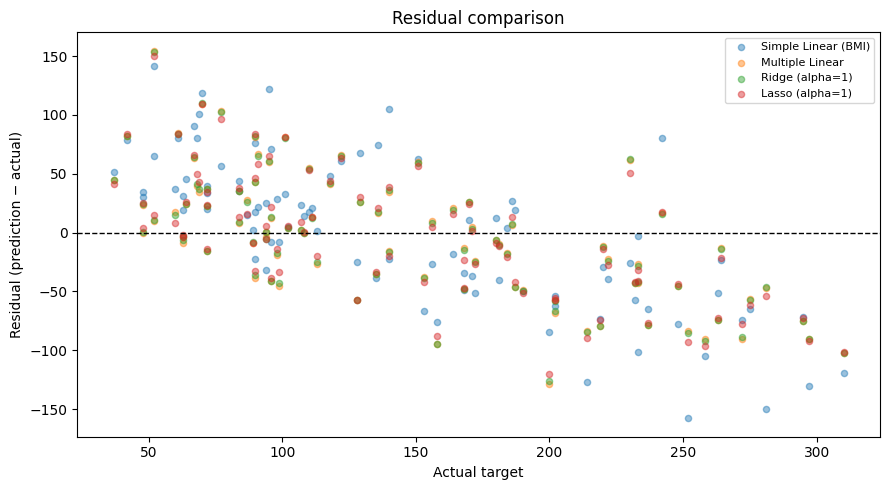

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(results_df['Model'], results_df['RMSE'])
ax.invert_yaxis(); ax.set(xlabel='Test RMSE (lower is better)', title='Test error comparison')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'model_rmse_comparison.png', dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for name in ['Simple Linear (BMI)', 'Multiple Linear', 'Ridge (alpha=1)', 'Lasso (alpha=1)']:
    ax.scatter(y_test, predictions[name] - y_test, alpha=0.45, s=20, label=name)
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set(xlabel='Actual target', ylabel='Residual (prediction − actual)', title='Residual comparison')
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'residual_comparison.png', dpi=160); plt.show()

## Regularization: influence of alpha
Higher `alpha` means stronger shrinkage. We fit each model across several values using the same training data and show test RMSE. These curves are descriptive; selecting an optimal alpha rigorously would require cross-validation on training data, rather than choosing from test results.

,Method,Alpha,Test RMSE,Train R²
0,Ridge,0.001,53.853,0.528
1,Ridge,0.010,53.852,0.528
2,Ridge,0.100,53.843,0.528
3,Ridge,1.000,53.777,0.528
4,Ridge,10.000,53.626,0.525
5,Ridge,100.000,53.462,0.512
6,Lasso,0.001,53.852,0.528
7,Lasso,0.010,53.836,0.528
8,Lasso,0.100,53.709,0.527
9,Lasso,1.000,53.147,0.523


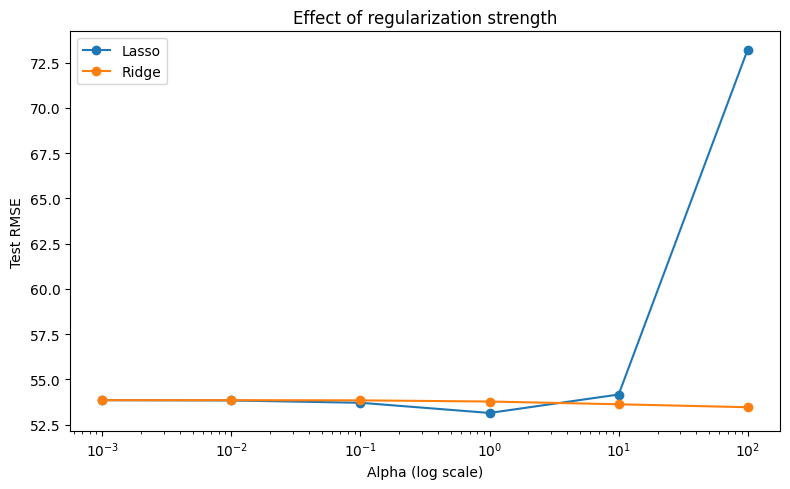

In [7]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
regularization_rows = []
for method, estimator in [('Ridge', Ridge), ('Lasso', Lasso)]:
    for alpha in alphas:
        pipeline = make_pipeline(StandardScaler(), estimator(alpha=alpha, max_iter=20000) if method == 'Lasso' else estimator(alpha=alpha))
        pipeline.fit(X_train, y_train)
        pred = pipeline.predict(X_test)
        regularization_rows.append({'Method': method, 'Alpha': alpha, 'Test RMSE': np.sqrt(mean_squared_error(y_test, pred)), 'Train R²': r2_score(y_train, pipeline.predict(X_train))})
reg_df = pd.DataFrame(regularization_rows)
display(reg_df.round(3))
fig, ax = plt.subplots()
for method, group in reg_df.groupby('Method'):
    ax.plot(group['Alpha'], group['Test RMSE'], marker='o', label=method)
ax.set_xscale('log'); ax.set(xlabel='Alpha (log scale)', ylabel='Test RMSE', title='Effect of regularization strength')
ax.legend(); fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'regularization_alpha.png', dpi=160); plt.show()

## Polynomial degree and overfitting
We compare polynomial degrees 1 through 8 using BMI only. A large train/test performance gap can indicate overfitting; the plot shows whether added complexity improves generalization.

,Degree,Train RMSE,Test RMSE
0,1,62.082,63.732
1,2,62.043,63.914
2,3,62.036,63.753
3,4,61.896,65.009
4,5,61.837,63.921
5,6,61.768,63.084
6,7,61.675,64.754
7,8,61.116,88.743


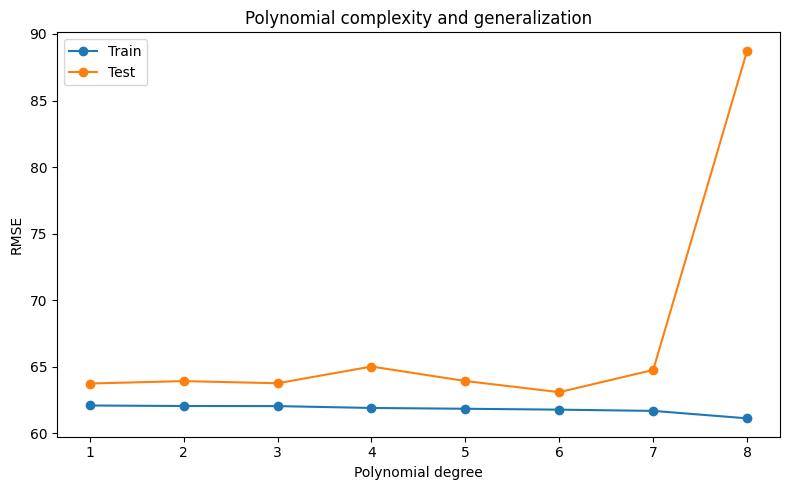

In [8]:
poly_rows = []
for degree in range(1, 9):
    model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())
    model.fit(X_train[['bmi']], y_train)
    poly_rows.append({'Degree': degree, 'Train RMSE': np.sqrt(mean_squared_error(y_train, model.predict(X_train[['bmi']]))), 'Test RMSE': np.sqrt(mean_squared_error(y_test, model.predict(X_test[['bmi']])))})
poly_df = pd.DataFrame(poly_rows)
display(poly_df.round(3))
fig, ax = plt.subplots()
ax.plot(poly_df['Degree'], poly_df['Train RMSE'], marker='o', label='Train')
ax.plot(poly_df['Degree'], poly_df['Test RMSE'], marker='o', label='Test')
ax.set(xlabel='Polynomial degree', ylabel='RMSE', title='Polynomial complexity and generalization')
ax.legend(); fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'polynomial_degrees.png', dpi=160); plt.show()

## Analysis and conclusions

In [9]:
best = results_df.iloc[0]
print(f"Lowest held-out RMSE: {best['Model']} ({best['RMSE']:.2f}); test R² = {best['R²']:.3f}.")
print('Model ranking by test RMSE:')
for i, row in results_df.iterrows():
    print(f"{i+1}. {row['Model']}: RMSE {row['RMSE']:.2f}, MAE {row['MAE']:.2f}, R² {row['R²']:.3f}")
print('Train-test R² gaps (positive can indicate overfitting):')
for _, row in results_df.iterrows():
    print(f"{row['Model']}: {row['Train R²']-row['R²']:.3f}")

Lowest held-out RMSE: Lasso (alpha=1) (53.15); test R² = 0.467.
Model ranking by test RMSE:
1. Lasso (alpha=1): RMSE 53.15, MAE 42.80, R² 0.467
2. Ridge (alpha=1): RMSE 53.78, MAE 42.81, R² 0.454
3. Multiple Linear: RMSE 53.85, MAE 42.79, R² 0.453
4. Simple Linear (BMI): RMSE 63.73, MAE 52.26, R² 0.233
5. Polynomial Degree 2 (BMI): RMSE 63.91, MAE 52.38, R² 0.229
Train-test R² gaps (positive can indicate overfitting):
Lasso (alpha=1): 0.056
Ridge (alpha=1): 0.073
Multiple Linear: 0.075
Simple Linear (BMI): 0.132
Polynomial Degree 2 (BMI): 0.138


**Interpretation guide:** The best model is identified by the smallest held-out RMSE above, rather than assumed in advance. Compare its R² and MAE with the alternatives. Simple linear regression has limited information because it uses BMI alone; multiple regression considers all ten predictors. Degree-2 polynomial regression adds a nonlinear BMI term, which may or may not improve held-out performance. Ridge reduces large coefficients through an L2 penalty, while Lasso can shrink some coefficients exactly to zero through an L1 penalty. Very strong regularization can underfit; very high polynomial degree can overfit. The dataset is modest in size, so these results should not be treated as clinical predictions.

**Decisions and challenges:** A fixed random seed makes the split reproducible. Pipelines prevent scaling leakage. BMI-only polynomial regression keeps the degree comparison interpretable. We compare the same test set across models and avoid using test performance as a substitute for cross-validated hyperparameter tuning.

**References:** Scikit-learn developers. (n.d.). *Diabetes dataset* and *linear models*. https://scikit-learn.org/stable/